#Algorithm Comparison Notebook

##D. Evaluate Algorithm

D1. Which algorithm families suit the task?

The project will compare three classification algorithms from different families:
1. Decision Tree Classifier – selected as the primary algorithm because it produces understandable decision rules.
2. Logistic Regression – a linear classification algorithm that provides a useful comparison for identifying relationships between patient features and disease categories.
3. K-Nearest Neighbors (KNN) – a distance-based algorithm that classifies records based on similar patient profiles.
A majority-class classifier will also be included as the baseline.

##Import evaluation tools

The necessary machine learning algorithms and evaluation tools will be imported. Stratified K-Fold cross-validation will be used to evaluate the models using the same training data and evaluation metrics.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic

/content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic


In [3]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic/PythonEnvi_AI/Datasets/Disease_symptom_and_patient_profile_dataset.csv")
print(df.shape)
print(df.columns.tolist())

(349, 10)
['Disease', 'Fever', 'Cough', 'Fatigue', 'Difficulty Breathing', 'Age', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Outcome Variable']


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

from sklearn.model_selection import (
    StratifiedKFold, cross_validate, cross_val_predict, train_test_split
)
from sklearn.metrics import (
    make_scorer, recall_score, precision_score, f1_score, accuracy_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
print("Random seed:", RANDOM_STATE)

Random seed: 42


In [8]:

TARGET = "Disease"
MIN_RECORDS = 7

df = pd.read_csv("/content/drive/MyDrive/ColabNotebooks/ICT110_Disease_Diagnostic/PythonEnvi_AI/Datasets/Disease_symptom_and_patient_profile_dataset.csv")
print("Raw shape:", df.shape, "| diseases:", df[TARGET].nunique())


df[TARGET] = df[TARGET].replace({
    "Chronic Obstructive Pulmonary...": "Chronic Obstructive Pulmonary Disease (COPD)",
    "Urinary Tract Infection (UTI)": "Urinary Tract Infection",
})


n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows removed:", n_dup, "| shape now:", df.shape)


counts = df[TARGET].value_counts()
kept = counts[counts >= MIN_RECORDS].index
print(f"Diseases with < {MIN_RECORDS} records removed:", (counts < MIN_RECORDS).sum(),
      "| diseases kept:", len(kept))
df = df[df[TARGET].isin(kept)].reset_index(drop=True)
print("Modelling data:", df.shape)


X = df.drop(columns=[TARGET])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test (not used here):", X_test.shape)
print("\nTraining records per disease:")
print(y_train.value_counts())

Raw shape: (349, 10) | diseases: 116
Duplicate rows removed: 49 | shape now: (300, 10)
Diseases with < 7 records removed: 104 | diseases kept: 10
Modelling data: (98, 10)
Train: (78, 9) | Test (not used here): (20, 9)

Training records per disease:
Disease
Asthma                     13
Osteoporosis                9
Stroke                      9
Migraine                    8
Diabetes                    8
Hypertension                8
Urinary Tract Infection     6
Influenza                   6
Pneumonia                   6
Bronchitis                  5
Name: count, dtype: int64


##Define the candidate algorithms

Four models will be prepared for comparison. The majority-class classifier will establish the baseline performance, while Decision Tree, Logistic Regression, and KNN will be evaluated as candidate algorithms.

In [9]:
models = {
    "Majority Class Baseline": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, weights="distance"),
}

print("Candidate models:")
for name in models:
    print("-", name)

Candidate models:
- Majority Class Baseline
- Decision Tree
- Logistic Regression
- K-Nearest Neighbors


##Set up stratified cross-validation

Stratified K-Fold cross-validation will be used to maintain approximately equal disease-category proportions across the folds. Five folds will be used when every disease category has at least five training records.

In [10]:
class_counts = y_train.value_counts()
min_class_size = int(class_counts.min())
print("Smallest class size:", min_class_size, "| class:", class_counts.idxmin())

n_splits = min(5, min_class_size)
assert n_splits >= 2, (
    f"Class '{class_counts.idxmin()}' has only {min_class_size} training "
    "record(s); at least 2 are needed for stratified cross-validation."
)

cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
print("Number of cross-validation folds:", n_splits)

Smallest class size: 5 | class: Bronchitis
Number of cross-validation folds: 5


##Create complete model pipelines

Each candidate algorithm will be combined with the same preprocessing pipeline. This ensures that imputation, encoding, and scaling are performed within each cross-validation training fold, preventing data leakage.

In [11]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_cols),
])

pipelines = {
    name: Pipeline([("preprocessor", clone(preprocessor)), ("model", model)])
    for name, model in models.items()
}
print("\nPipelines created:")
for name in pipelines:
    print("-", name)

Numeric columns: ['Age']
Categorical columns: ['Fever', 'Cough', 'Fatigue', 'Difficulty Breathing', 'Gender', 'Blood Pressure', 'Cholesterol Level', 'Outcome Variable']

Pipelines created:
- Majority Class Baseline
- Decision Tree
- Logistic Regression
- K-Nearest Neighbors


##Define evaluation metrics

Macro-Averaged Recall will serve as the primary evaluation metric. Accuracy, Macro Precision, and Macro F1-score will be used as secondary metrics to provide a broader understanding of model performance.

In [12]:
scoring = {
    "macro_recall": "recall_macro",
    "accuracy": "accuracy",
    "macro_precision": "precision_macro",
    "macro_f1": "f1_macro",
}
print("Primary metric: macro_recall")
print("Secondary metrics: accuracy, macro_precision, macro_f1")

Primary metric: macro_recall
Secondary metrics: accuracy, macro_precision, macro_f1


##Perform cross-validation

Each model will be evaluated using the same stratified folds. The mean and standard deviation of each evaluation metric will be calculated to compare both model performance and consistency.

In [13]:
cv_results, rows = {}, []

for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, error_score='raise')
    cv_results[name] = scores
    row = {"Model": name}
    for m in scoring:
        v = scores[f"test_{m}"]
        row[f"{m} mean"] = v.mean()
        row[f"{m} std"] = v.std()
    rows.append(row)

summary_df = (
    pd.DataFrame(rows).set_index("Model").sort_values("macro_recall mean", ascending=False)
)
summary_df.round(4)

,macro_recall mean,macro_recall std,accuracy mean,accuracy std,macro_precision mean,macro_precision std,macro_f1 mean,macro_f1 std
Model,,,,,,,,
K-Nearest Neighbors,0.2033,0.0997,0.2192,0.0976,0.1720,0.0801,0.1698,0.0804
Logistic Regression,0.2000,0.1085,0.2200,0.1321,0.1790,0.0835,0.1758,0.0941
Decision Tree,0.1900,0.1088,0.2075,0.1011,0.1907,0.1278,0.1777,0.1081
Majority Class Baseline,0.1000,0.0000,0.1658,0.0265,0.0166,0.0027,0.0284,0.0039


##Visualize algorithm comparison

A boxplot will be generated to compare the Macro Recall scores across cross-validation folds. This visualization will help determine whether the models perform consistently or have considerable variation between folds.

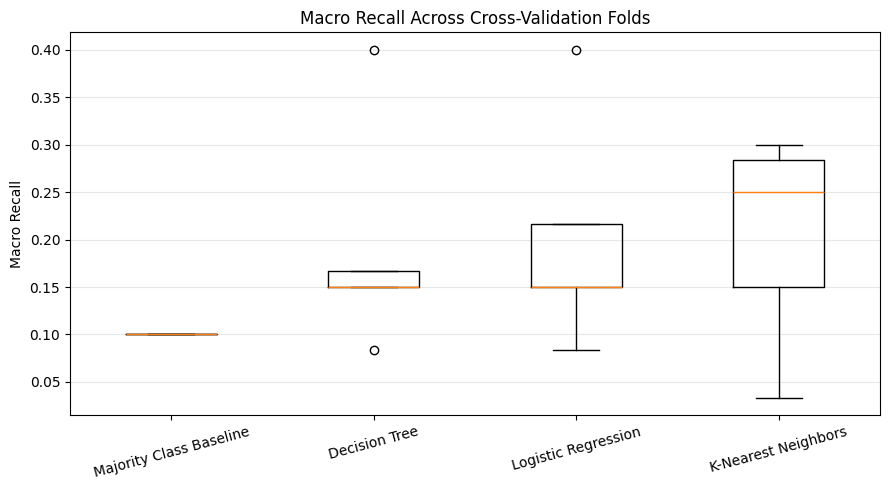

In [14]:
names = list(cv_results)
data = [cv_results[n]["test_macro_recall"] for n in names]

plt.figure(figsize=(9, 5))
plt.boxplot(data)
plt.xticks(range(1, len(names) + 1), names, rotation=15)
plt.ylabel("Macro Recall")
plt.title("Macro Recall Across Cross-Validation Folds")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##Identify the best candidate model

The model with the highest mean Macro Recall will be selected as the current best candidate. Its standard deviation will also be considered to evaluate the consistency of its performance across the validation folds.

In [15]:
if summary_df["macro_recall mean"].isna().all():
    raise RuntimeError(
        "All Macro Recall scores are NaN, so the models failed during cross-validation. "
        "Re-run the 'Perform cross-validation' cell with error_score='raise' to see the real error."
    )

candidates = summary_df.drop(index="Majority Class Baseline")
best_name = candidates["macro_recall mean"].idxmax()
best_mean = candidates.loc[best_name, "macro_recall mean"]
best_std = candidates.loc[best_name, "macro_recall std"]
baseline_mean = summary_df.loc["Majority Class Baseline", "macro_recall mean"]


best_pipeline = pipelines[best_name]
best_model_name = best_name

print("Best candidate model:", best_name)
print(f"Mean Macro Recall: {best_mean:.4f}")
print(f"Std of Macro Recall: {best_std:.4f}")
print(f"Baseline Macro Recall: {baseline_mean:.4f}")
print(f"Improvement over baseline: {best_mean - baseline_mean:.4f}")

Best candidate model: K-Nearest Neighbors
Mean Macro Recall: 0.2033
Std of Macro Recall: 0.0997
Baseline Macro Recall: 0.1000
Improvement over baseline: 0.1033


##Examine individual cross-validation results

The individual Macro Recall scores from each fold will be examined to identify differences in model performance and possible instability.

In [16]:
for name, scores in cv_results.items():
    print("\nModel:", name)
    for fold_number, score in enumerate(
        scores["test_macro_recall"], start=1
    ):
        print(f"Fold {fold_number}: {score:.4f}")
    print(
        "Mean:",
        round(scores["test_macro_recall"].mean(), 4)
    )
    print(
        "Standard Deviation:",
        round(scores["test_macro_recall"].std(), 4)
    )


Model: Majority Class Baseline
Fold 1: 0.1000
Fold 2: 0.1000
Fold 3: 0.1000
Fold 4: 0.1000
Fold 5: 0.1000
Mean: 0.1
Standard Deviation: 0.0

Model: Decision Tree
Fold 1: 0.1667
Fold 2: 0.0833
Fold 3: 0.1500
Fold 4: 0.4000
Fold 5: 0.1500
Mean: 0.19
Standard Deviation: 0.1088

Model: Logistic Regression
Fold 1: 0.0833
Fold 2: 0.2167
Fold 3: 0.1500
Fold 4: 0.4000
Fold 5: 0.1500
Mean: 0.2
Standard Deviation: 0.1085

Model: K-Nearest Neighbors
Fold 1: 0.0333
Fold 2: 0.2833
Fold 3: 0.3000
Fold 4: 0.2500
Fold 5: 0.1500
Mean: 0.2033
Standard Deviation: 0.0997


##Cross-validation confusion matrix

The selected candidate model will be examined using out-of-fold predictions from the training dataset. A confusion matrix will be generated to identify disease categories that are frequently misclassified. These predictions will not use the held-out test set.

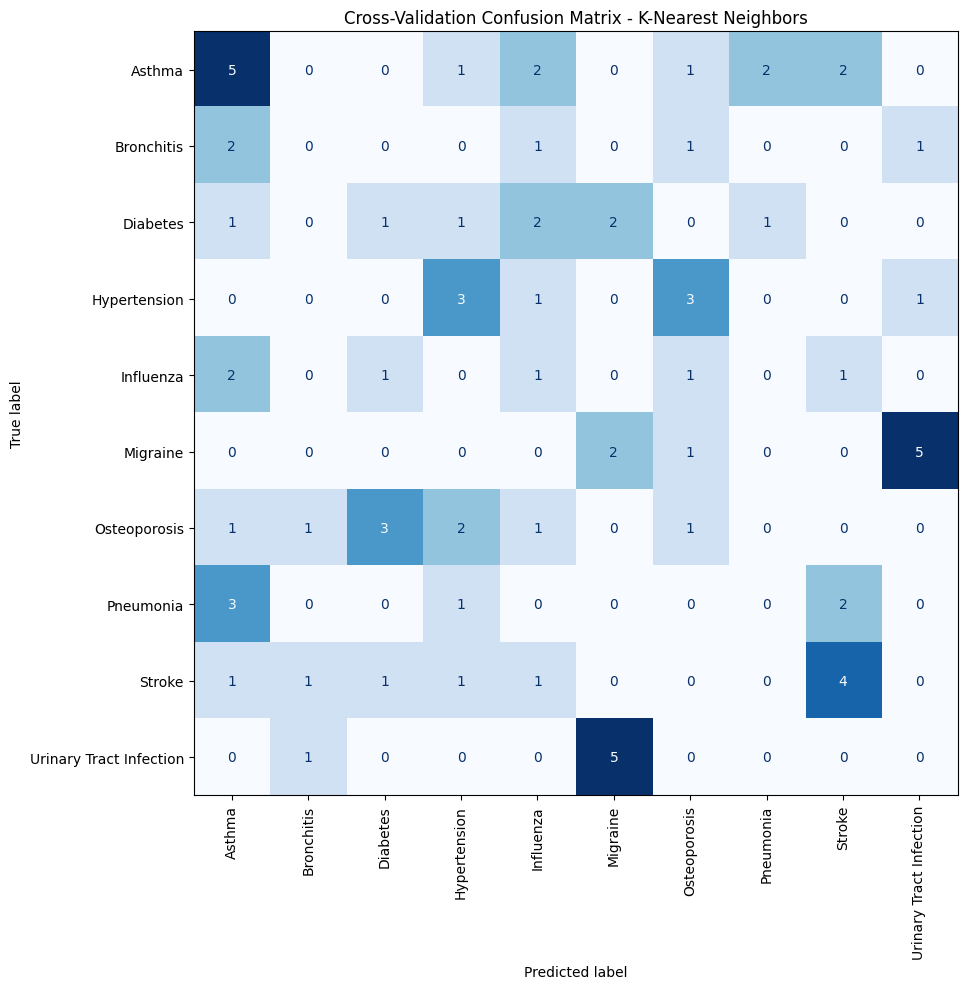

In [17]:
from sklearn.model_selection import cross_val_predict

oof_predictions = cross_val_predict(
    best_pipeline,
    X_train,
    y_train,
    cv=cv,
    n_jobs=-1
)


class_labels = np.unique(y_train)

cm = confusion_matrix(
    y_train,
    oof_predictions,
    labels=class_labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    ax=ax,
    colorbar=False
)

plt.title(
    f"Cross-Validation Confusion Matrix - {best_model_name}"
)

plt.tight_layout()
plt.show()

##Classification report

A classification report will be generated using out-of-fold predictions. It will show precision, recall, and F1-score for each disease category, allowing the group to identify which categories require further improvement.

In [18]:
print("Classification Report:")
print(
    classification_report(
        y_train,
        oof_predictions,
        zero_division=0
    )
)

Classification Report:
                         precision    recall  f1-score   support

                 Asthma       0.33      0.38      0.36        13
             Bronchitis       0.00      0.00      0.00         5
               Diabetes       0.17      0.12      0.14         8
           Hypertension       0.33      0.38      0.35         8
              Influenza       0.11      0.17      0.13         6
               Migraine       0.22      0.25      0.24         8
           Osteoporosis       0.12      0.11      0.12         9
              Pneumonia       0.00      0.00      0.00         6
                 Stroke       0.44      0.44      0.44         9
Urinary Tract Infection       0.00      0.00      0.00         6

               accuracy                           0.22        78
              macro avg       0.17      0.19      0.18        78
           weighted avg       0.20      0.22      0.21        78



###Answers for Section D

D1. Which algorithm families suit your task, data size and feature types?

The project selected Decision Tree, Logistic Regression, and K-Nearest Neighbors because they represent different approaches to classification. Decision Tree provides interpretable decision rules, Logistic Regression provides a linear classification approach, and KNN classifies records based on similarities between patient profiles. A majority-class classifier is included as the baseline.

D2. What assumptions does each candidate make?
- Decision Tree: Uses feature-based decision rules and can model nonlinear relationships. It may overfit if not properly controlled.
- Logistic Regression: Assumes a linear relationship between the input features and the log-odds of the classes. It may require additional feature engineering when relationships are nonlinear.
- KNN: Assumes that similar records have similar outcomes. It is sensitive to feature scaling and irrelevant features.
D3. What validation scheme did you use and why?

Stratified K-Fold cross-validation was selected because the project involves multiclass classification. It helps maintain the distribution of disease categories across the training and validation folds. The models will use identical folds to ensure a fair comparison.

D4. How do candidates compare with the baseline?

The candidate algorithms will be compared with the majority-class baseline using Macro Recall, Macro Precision, Macro F1-score, and Accuracy. The mean and standard deviation of the cross-validation scores will be examined to determine whether the models improve over the baseline and whether the differences are consistent across folds.

D5. Which model do you shortlist?

The model with the highest mean Macro Recall will be shortlisted, while its consistency, interpretability, training requirements, and prediction cost will also be considered. Decision Tree remains the primary proposed algorithm because its decision rules are relatively easy to interpret for healthcare decision support.

D6. Where does the shortlisted model fail?

The model's weaknesses will be identified using its cross-validation confusion matrix and classification report. Disease categories with lower recall will be examined because they represent conditions the model frequently fails to identify correctly.